Name: Sania  
CMS ID: 023-24-0277  
Section: H  
GitHub Profile: https://github.com/saniamirani   
Kaggle Profile: https://www.kaggle.com/saniam58  
Dataset: clean_churn.csv  
Dataset Source: Dataset produced after EDA analysis

In [2]:
#task1
import pandas as pd
df=pd.read_csv("clean_churn.csv")
df.shape
df.info()
df['Churn'].value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

Churn
No     5174
Yes    1869
Name: count, dtype: int64

#task2
Company wants to predict the churn of a given customer to find a way to retain them.

In [3]:
#task3,4
y=df["Churn"].map({"Yes":1, "No":0})
X=df.drop(columns=["Churn"])
X=pd.get_dummies(X, columns=["gender","Partner","Dependents","PhoneService",
                              "MultipleLines","InternetService","OnlineSecurity","OnlineBackup",
                              "DeviceProtection","TechSupport","StreamingTV","StreamingMovies","Contract",
                              "PaperlessBilling","PaymentMethod"], dtype=int)

Manual mapping is used for y because Churn is a binary categorical variable with only two values. One-hot encoding is used for X because it contains multiple categorical features, and it efficiently converts their categories into numerical 0/1 columns.

In [4]:
#Task5
print(X.dtypes)
print(X.isnull().sum().sum())

SeniorCitizen                                int64
tenure                                       int64
MonthlyCharges                             float64
TotalCharges                               float64
gender_Female                                int64
gender_Male                                  int64
Partner_No                                   int64
Partner_Yes                                  int64
Dependents_No                                int64
Dependents_Yes                               int64
PhoneService_No                              int64
PhoneService_Yes                             int64
MultipleLines_No                             int64
MultipleLines_No phone service               int64
MultipleLines_Yes                            int64
InternetService_DSL                          int64
InternetService_Fiber optic                  int64
InternetService_No                           int64
OnlineSecurity_No                            int64
OnlineSecurity_No internet serv

In [5]:
#task6
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20, random_state=42 , stratify=y)


_stratify=y is sensible because Churn has class imbalance. It ensures the training and test sets maintain approximately the same proportion of Churn classes as the original dataset, giving a fairer evaluation._

In [6]:
#task7
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(5634, 45)
(1409, 45)
(5634,)
(1409,)


In [7]:
#task8
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print("Tree depth:", model.get_depth())

Tree depth: 23


#task9
depth = 23.

_That is fairly deep for a default decision tree. It can be surprising because scikit-learn’s default settings allow the tree to keep splitting until the stopping conditions are reached, which can lead to overfitting._

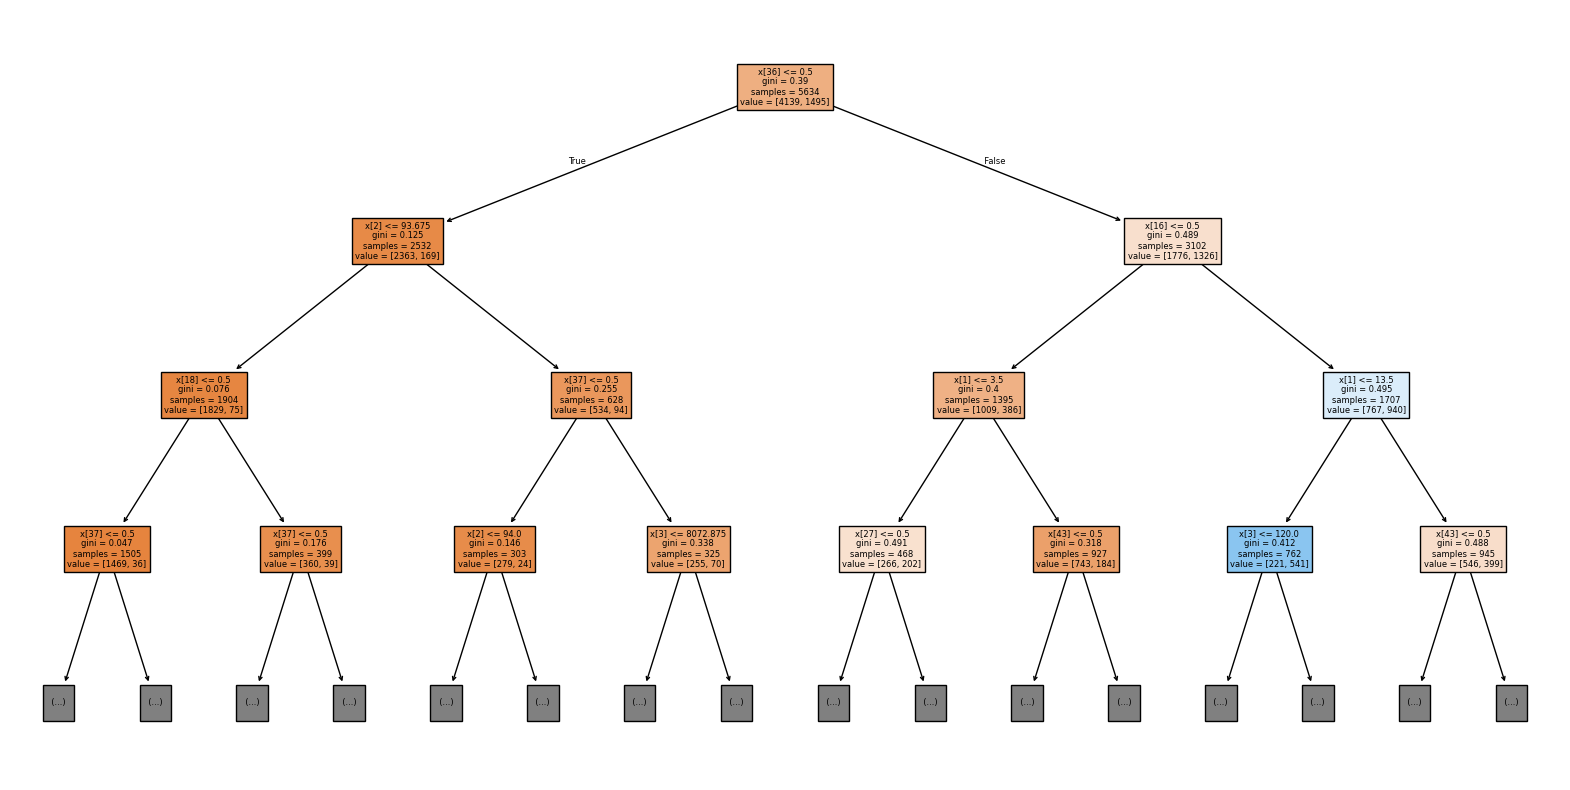

In [8]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))
plot_tree(model, max_depth=3, filled=True)
plt.show()

In [9]:
#task 10
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1-score:", f1_score(y_test, y_test_pred))

Accuracy: 0.7196593328601846
Precision: 0.4730077120822622
Recall: 0.4919786096256685
F1-score: 0.48230668414154654


[[830 205]
 [190 184]]


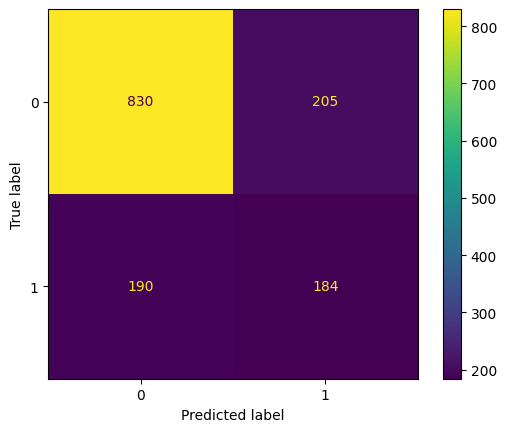

In [10]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_test_pred)
print(cm)
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred)
plt.show()


_Answer11: Out of 374 actual churners, the model caught 184 and missed 190._

_Answer12: F1-score: Useful because it balances precision and recall, especially when the classes are imbalanced._

In [11]:
print("Training accuracy:", accuracy_score(y_train, y_train_pred))
print("Test accuracy:", accuracy_score(y_test, y_test_pred))

Training accuracy: 0.9980475683351083
Test accuracy: 0.7196593328601846


_Answer 13: 27.8% is a large gap. This strongly suggests the Decision Tree is overfitting, it performs extremely well on training data but much worse on unseen test data._

In [12]:
#task 14
depths = [2, 3, 4, 5, 6, 8, 10, None]
results = []

for depth in depths:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X_train, y_train)

    train_acc = model.score(X_train, y_train)
    test_acc = model.score(X_test, y_test)

    results.append({
        "Max Depth": depth,
        "Train Accuracy": train_acc,
        "Test Accuracy": test_acc
    })

results_df = pd.DataFrame(results)
results_df

,Max Depth,Train Accuracy,Test Accuracy
0,2.0,0.765353,0.750887
1,3.0,0.791445,0.782115
2,4.0,0.796592,0.792051
3,5.0,0.803869,0.798439
4,6.0,0.810437,0.791341
5,8.0,0.837238,0.774308
6,10.0,0.878417,0.757275
7,NaN,0.998048,0.719659


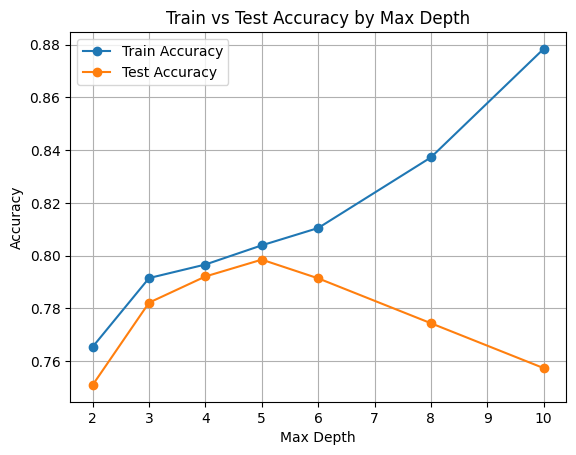

In [13]:
plt.plot(results_df["Max Depth"], results_df["Train Accuracy"], marker="o", label="Train Accuracy")
plt.plot(results_df["Max Depth"], results_df["Test Accuracy"], marker="o", label="Test Accuracy")

plt.xlabel("Max Depth")
plt.ylabel("Accuracy")
plt.title("Train vs Test Accuracy by Max Depth")
plt.legend()
plt.grid()
plt.show()

_Answer 15: Overfitting starts around when max_depth is 5.
At depth 5, test accuracy reaches its highest point. After that, training accuracy continues increasing, while test accuracy decreases. This growing gap indicates the model is fitting the training data too closely._

_Answer 16: I would select max_depth = 5. It gives the highest test accuracy while keeping the training accuracy very close to it, indicating good generalization and relatively little overfitting._

Accuracy: 0.7984386089425124
Precision: 0.6347305389221557
Recall: 0.5668449197860963
F1-score: 0.5988700564971752


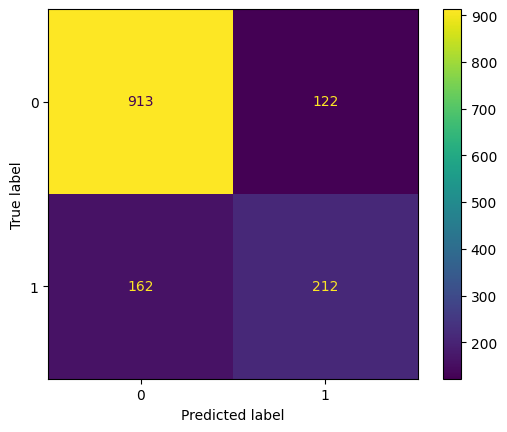

In [14]:
#task 17
model = DecisionTreeClassifier(max_depth=5, random_state=42)
model.fit(X_train, y_train)

y_test_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1-score:", f1_score(y_test, y_test_pred))

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred)
plt.show()

There is clear improvement over baseline tree.

Accuracy: 0.7366926898509581
Precision: 0.504
Recall: 0.5053475935828877
F1-score: 0.5046728971962616


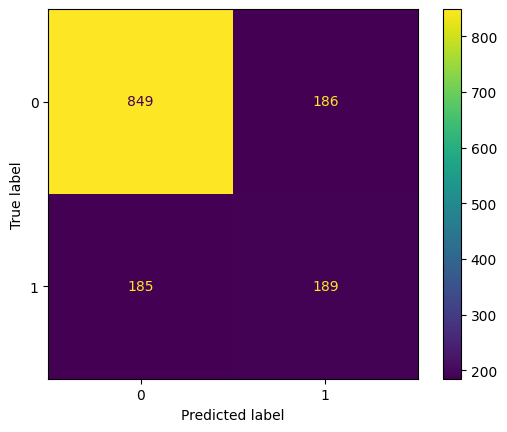

In [15]:
#task 18
model_entropy = DecisionTreeClassifier(criterion="entropy", random_state=42)
model_entropy.fit(X_train, y_train)

y_test_pred_entropy = model_entropy.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_test_pred_entropy))
print("Precision:", precision_score(y_test, y_test_pred_entropy))
print("Recall:", recall_score(y_test, y_test_pred_entropy))
print("F1-score:", f1_score(y_test, y_test_pred_entropy))

ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred_entropy)
plt.show()

Compared with the baseline (Gini), entropy performs better.

Contract_Month-to-month        0.513973
InternetService_Fiber optic    0.163262
tenure                         0.156717
TotalCharges                   0.036499
MonthlyCharges                 0.035922
dtype: float64


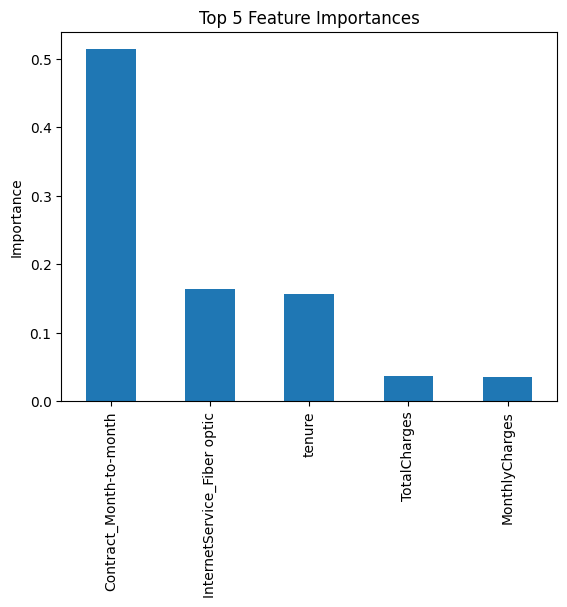

In [16]:
#task 19
feature_importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(feature_importance.head(5))

feature_importance.head(5).plot(kind="bar")
plt.title("Top 5 Feature Importances")
plt.ylabel("Importance")
plt.show()

_Interpretation:_

_The feature importance shows that Contract_Month-to-month (0.514) is by far the most influential feature, meaning it plays the biggest role in predicting churn. InternetService_Fiber optic (0.163) and tenure (0.157) are the next most important, while TotalCharges and MonthlyCharges have relatively small influence. Overall, the model suggests that contract type and internet service are stronger churn indicators than customer charges._



_Answer 20: In Lab 2, month-to-month contracts and fiber-optic service showed higher churn rates, while tenure and charges also differed between churned and non-churned customers, so their high feature importance supports the patterns observed during EDA._

_Answer 21: The final model selected was a Decision Tree with a maximum depth of 5. It achieved an accuracy of 79.84%, with a precision of 63.47%, recall of 56.68%, and F1-score of 59.89%. This was a clear improvement over the baseline model. However, the model still misses some churners, as shown by its moderate recall. Another limitation is that Decision Trees can be sensitive to the chosen depth and may overfit as complexity increases._

_Answer 22: Class imbalance should be a major next step, especially because churners are the minority class and our recall is only 56.68%._

In [17]:
#task 23
import math

data = {
    "Outlook": [
        "Sunny", "Sunny", "Overcast", "Rain", "Rain", "Rain",
        "Overcast", "Sunny", "Sunny", "Rain", "Sunny", "Overcast",
        "Overcast", "Rain"
    ],
    "Temperature": [
        "Hot", "Hot", "Hot", "Mild", "Cool", "Cool",
        "Cool", "Mild", "Cool", "Mild", "Mild", "Mild",
        "Hot", "Mild"
    ],
    "Humidity": [
        "High", "High", "High", "High", "Normal", "Normal",
        "Normal", "High", "Normal", "Normal", "Normal", "High",
        "Normal", "High"
    ],
    "Wind": [
        "Weak", "Strong", "Weak", "Weak", "Weak", "Strong",
        "Strong", "Weak", "Weak", "Weak", "Strong", "Strong",
        "Weak", "Strong"
    ],
    "Play": [
        "No", "No", "Yes", "Yes", "Yes", "No",
        "Yes", "No", "Yes", "Yes", "Yes", "Yes",
        "Yes", "No"
    ]
}

df = pd.DataFrame(data)



def entropy(data, target):
    values = data[target].value_counts()
    total = len(data)

    ent = 0

    for count in values:
        probability = count / total
        ent -= probability * math.log2(probability)

    return ent



def information_gain(data, attribute, target):
    total_entropy = entropy(data, target)
    weighted_entropy = 0

    for value in data[attribute].unique():
        subset = data[data[attribute] == value]

        weight = len(subset) / len(data)
        subset_entropy = entropy(subset, target)

        weighted_entropy += weight * subset_entropy

    return total_entropy - weighted_entropy

def print_gains(data, attributes, target, level=0):

    indent = "    " * level

    print(f"\n{indent}Dataset size: {len(data)}")
    print(f"{indent}Entropy: {entropy(data, target):.4f}")

    # Stop if pure
    if len(data[target].unique()) == 1:
        print(f"{indent}Leaf -> {data[target].iloc[0]}")
        return

    # Stop if no attributes remain
    if not attributes:
        majority = data[target].mode()[0]
        print(f"{indent}Leaf -> {majority}")
        return

    # Calculate gains
    gains = {}

    for attribute in attributes:
        gains[attribute] = information_gain(
            data, attribute, target
        )

        print(
            f"{indent}Gain({attribute}) = "
            f"{gains[attribute]:.4f}"
        )

    # Select best attribute
    best_attribute = max(gains, key=gains.get)

    print(
        f"{indent}Best split: {best_attribute} "
        f"(gain = {gains[best_attribute]:.4f})"
    )

    remaining_attributes = [
        a for a in attributes if a != best_attribute
    ]

    # Recursively split
    for value in data[best_attribute].unique():

        print(f"\n{indent}--- {best_attribute} = {value} ---")

        subset = data[data[best_attribute] == value]

        print_gains(
            subset,
            remaining_attributes,
            target,
            level + 1
        )


# -----------------------------
# Run ID3
# -----------------------------
attributes = [
    "Outlook",
    "Temperature",
    "Humidity",
    "Wind"
]

print("Initial Entropy:",
      round(entropy(df, "Play"), 4))

print_gains(
    df,
    attributes,
    "Play"
)

Initial Entropy: 0.9403

Dataset size: 14
Entropy: 0.9403
Gain(Outlook) = 0.2467
Gain(Temperature) = 0.0292
Gain(Humidity) = 0.1518
Gain(Wind) = 0.0481
Best split: Outlook (gain = 0.2467)

--- Outlook = Sunny ---

    Dataset size: 5
    Entropy: 0.9710
    Gain(Temperature) = 0.5710
    Gain(Humidity) = 0.9710
    Gain(Wind) = 0.0200
    Best split: Humidity (gain = 0.9710)

    --- Humidity = High ---

        Dataset size: 3
        Entropy: 0.0000
        Leaf -> No

    --- Humidity = Normal ---

        Dataset size: 2
        Entropy: 0.0000
        Leaf -> Yes

--- Outlook = Overcast ---

    Dataset size: 4
    Entropy: 0.0000
    Leaf -> Yes

--- Outlook = Rain ---

    Dataset size: 5
    Entropy: 0.9710
    Gain(Temperature) = 0.0200
    Gain(Humidity) = 0.0200
    Gain(Wind) = 0.9710
    Best split: Wind (gain = 0.9710)

    --- Wind = Weak ---

        Dataset size: 3
        Entropy: 0.0000
        Leaf -> Yes

    --- Wind = Strong ---

        Dataset size: 2
        E